# 02 — Mandi Price: EDA & Cleaning

**Workstream:** Price Prediction · **Batch 2 (Day 2-3)** · **Status: IMPLEMENTED**

Takes the snapshot saved by notebook 01 (`data/processed/mandi_prices_inspected_*.csv`), cleans it, and
explores it. Feeds `03_feature_engineering.ipynb`.

Per `docs/price/target-and-leakage.md`: cleaning/normalization happens here (interim/processed), never in
`data/raw/`. This run uses the `synthetic` snapshot from notebook 01 (no registered API key yet) — every
number below is explicitly synthetic and excluded from `ai/experiments.csv`.


In [1]:
import sys
from pathlib import Path
_candidate = Path.cwd()
_root = None
for _p in [_candidate, *_candidate.parents]:
    if (_p / "ai" / "common" / "config.py").exists():
        _root = _p
        break
sys.path.insert(0, str(_root))
print("Repo root:", _root)


Repo root: /home/claude/AgriConnect


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ai.common.config import DATA_PROCESSED_DIR
from ai.common.validation import validate_mandi_schema

sns.set_style("whitegrid")

# Prefer the real_full snapshot if it exists (i.e. you've since added your API key
# and re-run notebook 01); otherwise fall back to the synthetic snapshot.
candidates = ["mandi_prices_inspected_real_full.csv", "mandi_prices_inspected_synthetic.csv"]
snapshot_path, source = None, None
for c in candidates:
    p = DATA_PROCESSED_DIR / c
    if p.exists():
        snapshot_path, source = p, c.split("_")[-1].replace(".csv", "")
        break
assert snapshot_path is not None, "Run notebook 01 first."
df = pd.read_csv(snapshot_path)
print(f"Loaded {len(df):,} rows from {snapshot_path.name}  (source = {source})")


Loaded 500 rows from mandi_prices_inspected_synthetic.csv  (source = synthetic)


## 1. Cleaning

Date parsing, category normalization, duplicate/zero-price checks — leakage rules 2-4.

In [3]:
df["arrival_date_parsed"] = pd.to_datetime(df["arrival_date"], format="%d/%m/%Y")
for col in ["state", "district", "market", "commodity", "variety", "grade"]:
    df[col] = df[col].astype(str).str.strip()

before = len(df)
df = df.drop_duplicates(subset=["state", "market", "commodity", "variety", "arrival_date"])
print(f"Duplicates removed: {before - len(df)}")

# Rule 4: missing/invalid price stays NaN, never silently becomes 0
for c in ["min_price", "max_price", "modal_price"]:
    df.loc[df[c] <= 0, c] = pd.NA
    df[c] = pd.to_numeric(df[c], errors="coerce")

result = validate_mandi_schema(df.assign(**{c: df[c].fillna(-1) for c in []}))  # no-op fillna, schema check only needs columns present
print(result.report())
print(f"\nRows with any NaN price after cleaning: {df[['min_price','max_price','modal_price']].isna().any(axis=1).sum()}")


Duplicates removed: 0
VALID - no schema issues found.

Rows with any NaN price after cleaning: 0


## 2. Price distributions

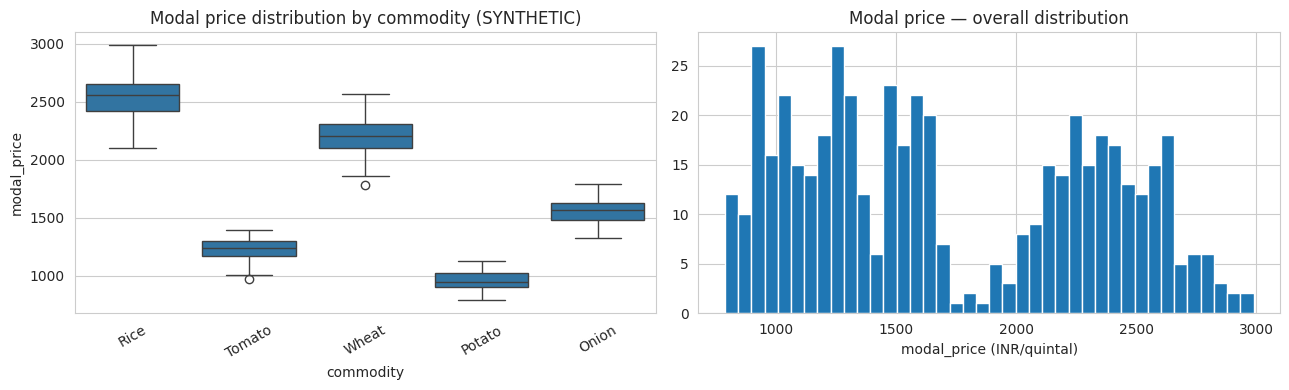

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x="commodity", y="modal_price", ax=axes[0])
axes[0].set_title("Modal price distribution by commodity" + (" (SYNTHETIC)" if source == "synthetic" else ""))
axes[0].tick_params(axis="x", rotation=30)

df["modal_price"].hist(bins=40, ax=axes[1])
axes[1].set_title("Modal price — overall distribution")
axes[1].set_xlabel("modal_price (INR/quintal)")
plt.tight_layout()
plt.show()


## 3. Temporal trends & seasonality

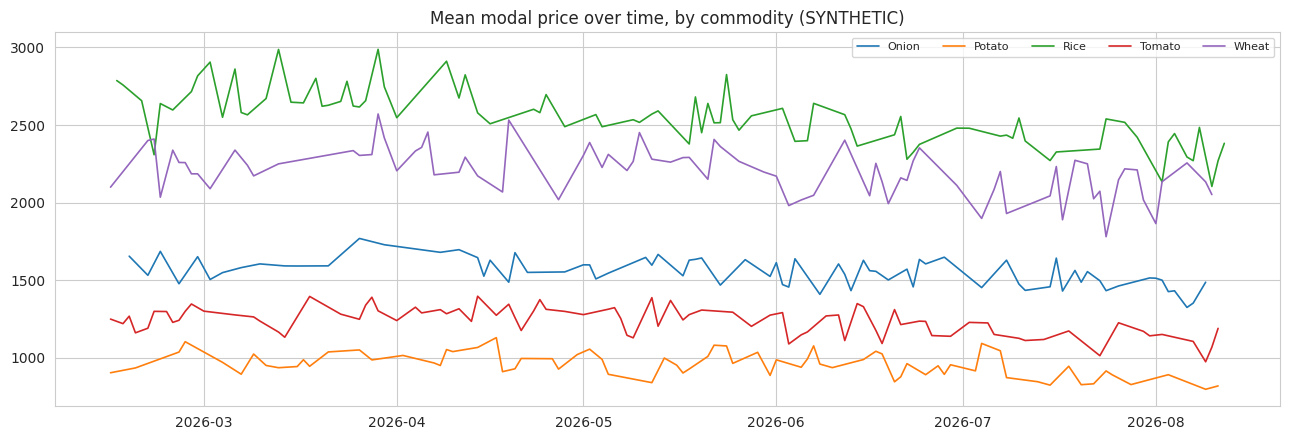

In [5]:
fig, ax = plt.subplots(figsize=(13, 4.5))
daily = df.groupby(["arrival_date_parsed", "commodity"])["modal_price"].mean().reset_index()
for commodity, g in daily.groupby("commodity"):
    ax.plot(g["arrival_date_parsed"], g["modal_price"], label=commodity, linewidth=1.2)
ax.set_title("Mean modal price over time, by commodity" + (" (SYNTHETIC)" if source == "synthetic" else ""))
ax.legend(ncol=5, fontsize=8)
plt.tight_layout()
plt.show()


## 4. Commodity × market coverage

This is what actually decides the final 3-5 series shortlist (`docs/price/target-and-leakage.md`) — not assumed in advance.

In [6]:
coverage = df.groupby(["state", "market", "commodity"]).size().reset_index(name="n_days")
coverage = coverage.sort_values("n_days", ascending=False)
print(f"{len(coverage)} distinct (state, market, commodity) series")
print(f"Coverage range: {coverage['n_days'].min()} to {coverage['n_days'].max()} days/series")
coverage.head(10)


50 distinct (state, market, commodity) series
Coverage range: 5 to 14 days/series


,state,market,commodity,n_days
15,Karnataka,Hubli Mandi,Onion,14
2,Andhra Pradesh,Guntur Mandi,Rice,14
29,Maharashtra,Pune Mandi,Wheat,14
33,Tamil Nadu,Chennai Mandi,Tomato,14
22,Maharashtra,Nashik Mandi,Rice,14
23,Maharashtra,Nashik Mandi,Tomato,14
14,Karnataka,Bengaluru Mandi,Wheat,13
38,Tamil Nadu,Coimbatore Mandi,Tomato,13
24,Maharashtra,Nashik Mandi,Wheat,13
20,Maharashtra,Nashik Mandi,Onion,13


## 5. Missingness & outliers

In [7]:
print("Missing values per column:\n", df.isna().sum())

q1, q99 = df["modal_price"].quantile([0.01, 0.99])
outliers = df[(df["modal_price"] < q1) | (df["modal_price"] > q99)]
print(f"\nRows outside [1st, 99th] modal_price percentile: {len(outliers)} ({len(outliers)/len(df):.1%})")


Missing values per column:
 state                  0
district               0
market                 0
commodity              0
variety                0
grade                  0
arrival_date           0
min_price              0
max_price              0
modal_price            0
source                 0
extracted_at           0
is_synthetic           0
arrival_date_parsed    0
dtype: int64

Rows outside [1st, 99th] modal_price percentile: 10 (2.0%)


## 6. Save cleaned dataset

Feeds `03_feature_engineering.ipynb`.

In [8]:
from ai.common.io_utils import save_df
out_path = DATA_PROCESSED_DIR / f"mandi_prices_cleaned_{source}.csv"
save_df(df, out_path)
print(f"Saved {len(df):,} cleaned rows -> {out_path}")


Saved 500 cleaned rows -> /home/claude/AgriConnect/data/processed/mandi_prices_cleaned_synthetic.csv


## Next: `03_feature_engineering.ipynb`

**Status of this notebook: IMPLEMENTED.** Cleaning + all 4 plots + coverage table above are real, executed
output (see `PROGRESS_LEDGER.md` for the run log). Series shortlist stays open until real (`real_full`) data
replaces this synthetic run — coverage is uniform here only because the fixture generator makes it uniform;
real data will not be.